# Does AI Trust Code or Comments?

**Phase 1 — Human-only pair**

Student ID: K12454514  
Second pair member: add name and student ID

This notebook tests whether comments influence a language model's judgement of Python code. It compares correct and buggy implementations, with no comment, an accurate comment, or a misleading comment.

## Setup

Install the required packages, connect Google Drive, load the data and model, then run the analysis sections in order.

In [ ]:
%pip install -q transformers accelerate pandas numpy matplotlib scipy scikit-learn tqdm

In [ ]:
import ast
import io
import re
import time
import tokenize

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from scipy.stats import spearmanr, wilcoxon
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer

STUDENT_ID = "K12454514"
MODEL_ID = "Qwen/Qwen2.5-Coder-1.5B-Instruct"
INPUT_PATH = "/content/drive/MyDrive/visualisation/controlled_inputs.csv"
RESULT_PATH = "/content/drive/MyDrive/visualisation/human_results.csv"


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
inputs_df = pd.read_csv(INPUT_PATH)

# Provided sanity checks on the input file
assert len(inputs_df) == 1068, len(inputs_df)
assert inputs_df["problem_id"].nunique() == 178
assert set(inputs_df["comment_type"]) == {"none", "accurate", "misleading"}
assert set(inputs_df["code_version"]) == {"correct", "buggy"}
assert not inputs_df[["problem_id", "code_version", "comment_type"]].duplicated().any()

inputs_df.head()

,problem_id,code_version,comment_type,bug_type,specification,code,code_length,ground_truth,annotation_status
0,11,correct,none,Eq_to_NotEq,Write a python function to remove first and la...,"def remove_Occ(s, ch):\n for i in range(len...",255,True,localized_operation_rule
1,11,correct,accurate,Eq_to_NotEq,Write a python function to remove first and la...,"def remove_Occ(s, ch):\n for i in range(len...",255,True,localized_operation_rule
2,11,correct,misleading,Eq_to_NotEq,Write a python function to remove first and la...,"def remove_Occ(s, ch):\n for i in range(len...",255,True,localized_operation_rule
3,11,buggy,none,Eq_to_NotEq,Write a python function to remove first and la...,"def remove_Occ(s, ch):\n for i in range(len...",255,False,localized_operation_rule
4,11,buggy,accurate,Eq_to_NotEq,Write a python function to remove first and la...,"def remove_Occ(s, ch):\n for i in range(len...",255,False,localized_operation_rule


In [ ]:
# Check GPU
assert torch.cuda.is_available(), "GPU not available. Enable GPU in Colab: Runtime > Change runtime type > T4 GPU"

print("GPU:", torch.cuda.get_device_name(0))

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Load model directly onto GPU
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="cuda:0"
)

model.eval()

print("Model device:", next(model.parameters()).device)
print("Model dtype:", next(model.parameters()).dtype)
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

GPU: Tesla T4


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model device: cuda:0
Model dtype: torch.float16
GPU memory allocated: 2.88 GB


## Inference (black-box, one forward pass per row)

In [ ]:
def single_token_id(word):
    ids = tokenizer.encode(word, add_special_tokens=False)
    assert len(ids) == 1, f"'{word}' is {len(ids)} tokens {ids}; pick another spelling"
    return ids[0]

YES_ID = single_token_id("Yes")
NO_ID  = single_token_id("No")
print("Yes ->", YES_ID, "| No ->", NO_ID)

print(repr(tokenizer.decode([YES_ID])), repr(tokenizer.decode([NO_ID])))

Yes -> 9454 | No -> 2753
'Yes' 'No'


In [ ]:
@torch.inference_mode()
def score_row(row):
    inputs = tokenizer.apply_chat_template(
        build_messages(
            row["specification"],
            row["code"]
        ),
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True,
    ).to(next(model.parameters()).device)

    logits = model(**inputs).logits[0, -1, :]

    two = torch.stack([
        logits[YES_ID],
        logits[NO_ID]
    ]).float()

    p_yes, p_no = torch.softmax(two, dim=0).tolist()

    return {
        "p_yes": p_yes,
        "p_no": p_no
    }

In [ ]:
SYSTEM_PROMPT = "You are a Python code reviewer. Answer Yes or No only."

def build_messages(specification, code_text):
    user_prompt = f"""Task specification:
{specification}

Python implementation:
```python
{code_text}
```

Does this implementation correctly satisfy the task specification?
Answer Yes or No only."""

    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_prompt},
    ]

In [ ]:
start_time = time.time()

metadata_cols = [
    "problem_id",
    "code_version",
    "comment_type",
    "bug_type",
    "code_length"
]

results = []
CHECKPOINT_INTERVAL = 50

for i, (_, row) in enumerate(inputs_df.iterrows()):

    scores = score_row(row)

    result = {col: row[col] for col in metadata_cols}
    result.update(scores)

    results.append(result)

    if (i + 1) % CHECKPOINT_INTERVAL == 0:
        pd.DataFrame(results).to_csv(RESULT_PATH, index=False)
        print(f"Checkpoint: {i + 1}/{len(inputs_df)}")

results_df = pd.DataFrame(results)
results_df.to_csv(RESULT_PATH, index=False)

total_runtime = time.time() - start_time

print(f"Completed: {len(results_df)} rows")
print(f"Runtime: {total_runtime:.2f} seconds")
print(f"Saved to: {RESULT_PATH}")

Checkpoint: 50/1068
Checkpoint: 100/1068
Checkpoint: 150/1068
Checkpoint: 200/1068
Checkpoint: 250/1068
Checkpoint: 300/1068
Checkpoint: 350/1068
Checkpoint: 400/1068
Checkpoint: 450/1068
Checkpoint: 500/1068
Checkpoint: 550/1068
Checkpoint: 600/1068
Checkpoint: 650/1068
Checkpoint: 700/1068
Checkpoint: 750/1068
Checkpoint: 800/1068
Checkpoint: 850/1068
Checkpoint: 900/1068
Checkpoint: 950/1068
Checkpoint: 1000/1068
Checkpoint: 1050/1068
Completed: 1068 rows
Runtime: 47.04 seconds
Saved to: /content/drive/MyDrive/visualisation/human_results.csv


In [ ]:
assert results_df is not None
assert len(results_df) == 1068
assert results_df["p_yes"].notna().all()
assert np.allclose(results_df["p_yes"] + results_df["p_no"], 1.0, atol=1e-4)
print(results_df["p_yes"].describe())

count    1068.000000
mean        0.854038
std         0.074338
min         0.338077
25%         0.833325
50%         0.870597
75%         0.899121
max         0.952574
Name: p_yes, dtype: float64


## 2. Reproducibility check

Compare our results with those from the AI-aided pair. This checks whether both runs contain the same cases and whether their confidence scores are similar.

In [ ]:
PAIR_RESULTS_PATH = "/content/drive/MyDrive/visualisation/controlled_results.csv"
COMPARISON_PATH = "/content/drive/MyDrive/visualisation/reproducibility_comparison.csv"


pair_df = pd.read_csv(PAIR_RESULTS_PATH)

print("Our results:", results_df.shape)
print("AI-aided pair results:", pair_df.shape)

merge_cols = ["problem_id", "code_version", "comment_type"]

assert not results_df.duplicated(subset=merge_cols).any(), "Duplicates in our results!"
assert not pair_df.duplicated(subset=merge_cols).any(), "Duplicates in pair results!"

comparison_df = results_df.merge(
    pair_df,
    on=merge_cols,
    how="outer",
    suffixes=("_mine", "_pair"),
    indicator=True,
    validate="one_to_one"
)

print("\nMatching status:")
print(comparison_df["_merge"].value_counts())

# Check all rows match
assert (comparison_df["_merge"] == "both").all(), \
    "Some rows are missing from one of the datasets!"

comparison_df["abs_diff"] = (
    comparison_df["p_yes_mine"] -
    comparison_df["p_yes_pair"]
).abs()

max_diff = comparison_df["abs_diff"].max()
mean_diff = comparison_df["abs_diff"].mean()

print("\n========== REPRODUCIBILITY RESULTS ==========")
print(f"Rows compared: {len(comparison_df)}")
print(f"Maximum absolute difference: {max_diff:.10f}")
print(f"Mean absolute difference:    {mean_diff:.10f}")

threshold = 0.01

large_diff = comparison_df[
    comparison_df["abs_diff"] > threshold
]

print(f"\nRows with difference > {threshold}: {len(large_diff)}")
print(f"Percentage: {len(large_diff) / len(comparison_df) * 100:.2f}%")

print("\nTop 10 largest differences:")

display(
    comparison_df.sort_values("abs_diff", ascending=False)[
        merge_cols + [
            "p_yes_mine",
            "p_yes_pair",
            "abs_diff"
        ]
    ].head(10)
)


comparison_df.to_csv(COMPARISON_PATH, index=False)

print("\nComparison saved to:", COMPARISON_PATH)

print("\n========== MODEL CONFIGURATION ==========")
print("Model:", MODEL_ID)
print("Device:", next(model.parameters()).device)
print("Dtype:", next(model.parameters()).dtype)
print("Tokenizer:", tokenizer.name_or_path)

print("\n========== INTERPRETATION ==========")

if max_diff < 0.001:
    print("Excellent agreement. Differences are very small.")
elif max_diff < 0.01:
    print("Good agreement. Small numerical differences may be expected.")
else:
    print("Large differences detected. Investigate prompts, token IDs, chat templates and dtype.")

print("==========================================")

Our results: (1068, 7)
AI-aided pair results: (1068, 11)

Matching status:
_merge
both          1068
left_only        0
right_only       0
Name: count, dtype: int64

========== REPRODUCIBILITY RESULTS ==========
Rows compared: 1068
Maximum absolute difference: 0.0000000000
Mean absolute difference:    0.0000000000

Rows with difference > 0.01: 0
Percentage: 0.00%

Top 10 largest differences:


,problem_id,code_version,comment_type,p_yes_mine,p_yes_pair,abs_diff
150,80,buggy,accurate,0.924142,0.924142,1.110223e-16
151,80,buggy,misleading,0.921922,0.921922,1.110223e-16
425,170,correct,none,0.919643,0.919643,1.110223e-16
923,436,correct,none,0.919643,0.919643,1.110223e-16
922,436,correct,misleading,0.908618,0.908618,1.110223e-16
685,292,buggy,misleading,0.901921,0.901921,1.110223e-16
158,82,buggy,none,0.924142,0.924142,1.110223e-16
159,82,correct,accurate,0.913677,0.913677,1.110223e-16
161,82,correct,none,0.935346,0.935346,1.110223e-16
635,280,correct,none,0.912436,0.912436,1.110223e-16



Comparison saved to: /content/drive/MyDrive/visualisation/reproducibility_comparison.csv

========== MODEL CONFIGURATION ==========
Model: Qwen/Qwen2.5-Coder-1.5B-Instruct
Device: cuda:0
Dtype: torch.float16
Tokenizer: Qwen/Qwen2.5-Coder-1.5B-Instruct

========== INTERPRETATION ==========
Excellent agreement. Differences are very small.


## 3. Question 1: can the model recognise buggy code?


Ground truth distribution:
ground_truth  False  True 
code_version              
buggy           534      0
correct           0    534

Positive class: Correct code (ground_truth=True)
Negative class: Buggy code (ground_truth=False)
Total rows: 1068


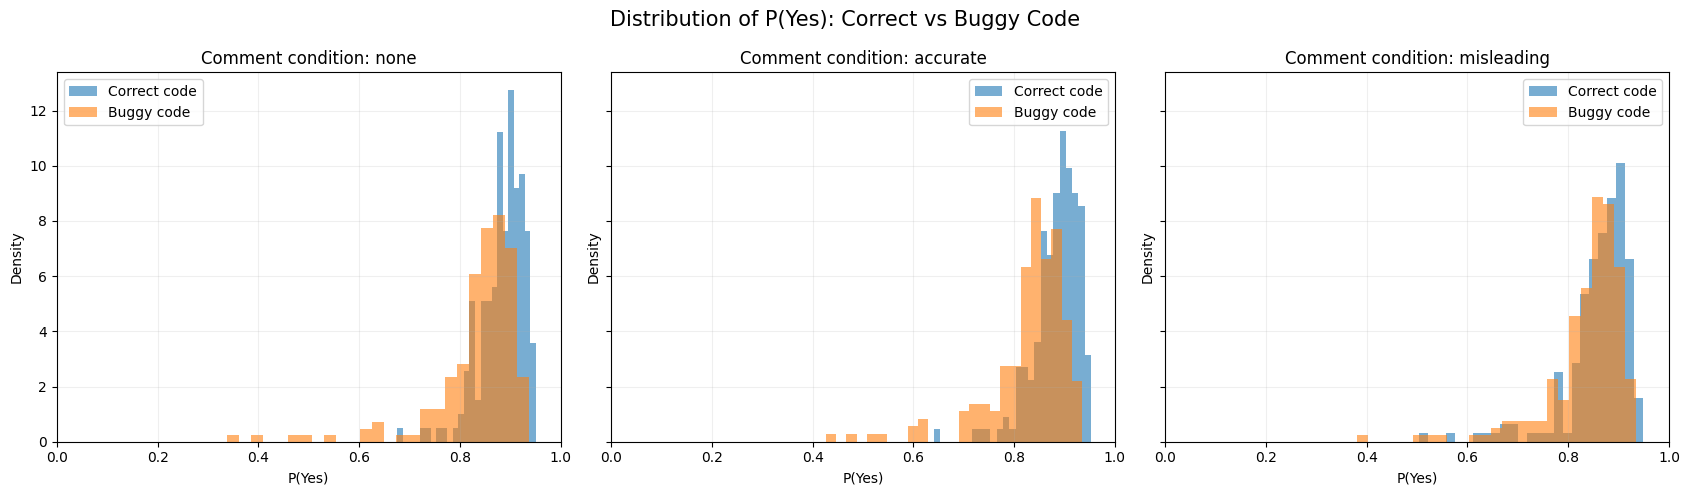


AUROC RESULTS:


,comment_type,AUROC,n_correct,n_buggy
0,none,0.728286,178,178
1,accurate,0.760084,178,178
2,misleading,0.621939,178,178



AUROC WITH 95% BOOTSTRAP CONFIDENCE INTERVALS:


,comment_type,AUROC,CI_lower,CI_upper,valid_bootstraps
0,none,0.728286,0.697555,0.761931,2000
1,accurate,0.760084,0.726198,0.795443,2000
2,misleading,0.621939,0.590832,0.655659,2000


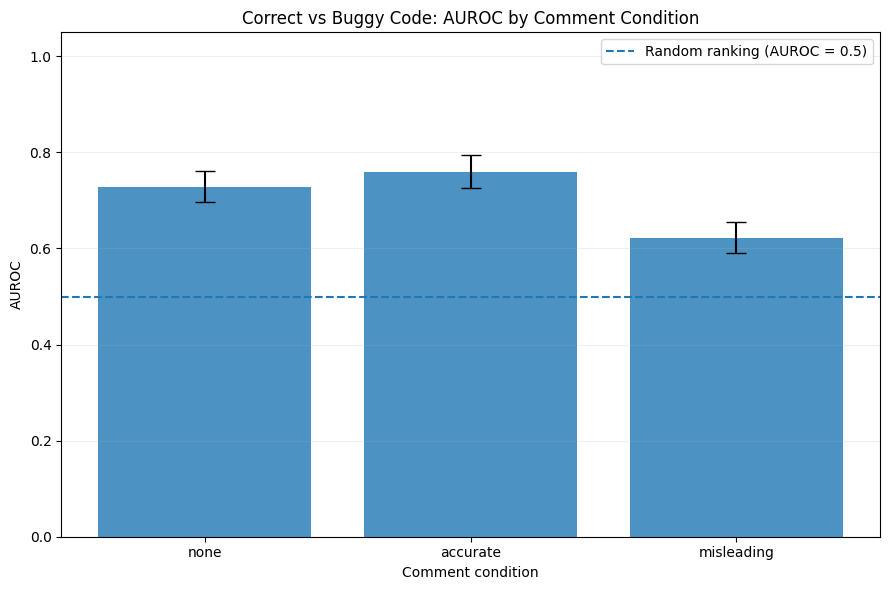


========== FINAL SUMMARY ==========
none         | AUROC: 0.7283 | 95% CI: [0.6976, 0.7619]
accurate     | AUROC: 0.7601 | 95% CI: [0.7262, 0.7954]
misleading   | AUROC: 0.6219 | 95% CI: [0.5908, 0.6557]

Interpretation:
- AUROC = 0.5: No ranking discrimination.
- AUROC > 0.5: Correct code tends to receive higher P(Yes).
- AUROC < 0.5: Buggy code tends to receive higher P(Yes).
- Compare the three conditions to investigate comment influence.

Analysis completed.


In [ ]:
merge_cols = ["problem_id", "code_version", "comment_type"]

analysis_df = results_df.merge(
    inputs_df[merge_cols + ["ground_truth"]],
    on=merge_cols,
    how="inner",
    validate="one_to_one"
)

assert len(analysis_df) == len(inputs_df), "Some rows are missing!"

print("Ground truth distribution:")
print(pd.crosstab(
    analysis_df["code_version"],
    analysis_df["ground_truth"]
))

assert (
    analysis_df.loc[
        analysis_df["code_version"] == "correct",
        "ground_truth"
    ].eq(True).all()
), "Check ground_truth mapping: True does not consistently mean correct!"

assert (
    analysis_df.loc[
        analysis_df["code_version"] == "buggy",
        "ground_truth"
    ].eq(False).all()
), "Check ground_truth mapping: False does not consistently mean buggy!"

analysis_df["y_true"] = (
    analysis_df["ground_truth"].astype(bool).astype(int)
)

print("\nPositive class: Correct code (ground_truth=True)")
print("Negative class: Buggy code (ground_truth=False)")
print("Total rows:", len(analysis_df))

conditions = ["none", "accurate", "misleading"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharex=True,
    sharey=True
)

for ax, condition in zip(axes, conditions):

    subset = analysis_df[
        analysis_df["comment_type"] == condition
    ]

    correct = subset.loc[
        subset["y_true"] == 1, "p_yes"
    ]

    buggy = subset.loc[
        subset["y_true"] == 0, "p_yes"
    ]

    ax.hist(
        correct,
        bins=25,
        alpha=0.6,
        density=True,
        label="Correct code"
    )

    ax.hist(
        buggy,
        bins=25,
        alpha=0.6,
        density=True,
        label="Buggy code"
    )

    ax.set_title(f"Comment condition: {condition}")
    ax.set_xlabel("P(Yes)")
    ax.set_ylabel("Density")
    ax.set_xlim(0, 1)
    ax.legend()
    ax.grid(alpha=0.2)

plt.suptitle(
    "Distribution of P(Yes): Correct vs Buggy Code",
    fontsize=15
)

plt.tight_layout()
plt.show()

auroc_results = []

for condition in conditions:

    subset = analysis_df[
        analysis_df["comment_type"] == condition
    ]

    y_true = subset["y_true"]
    y_score = subset["p_yes"]

    auc = roc_auc_score(y_true, y_score)

    auroc_results.append({
        "comment_type": condition,
        "AUROC": auc,
        "n_correct": (y_true == 1).sum(),
        "n_buggy": (y_true == 0).sum()
    })

auroc_df = pd.DataFrame(auroc_results)

print("\nAUROC RESULTS:")
display(auroc_df)


N_BOOTSTRAP = 2000
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

problem_ids = analysis_df["problem_id"].unique()

bootstrap_results = {
    condition: [] for condition in conditions
}

for b in range(N_BOOTSTRAP):

    sampled_ids = rng.choice(
        problem_ids,
        size=len(problem_ids),
        replace=True
    )

    sampled_parts = []

    for draw_id, problem_id in enumerate(sampled_ids):

        part = analysis_df[
            analysis_df["problem_id"] == problem_id
        ].copy()

        part["_bootstrap_cluster"] = draw_id
        sampled_parts.append(part)

    bootstrap_df = pd.concat(
        sampled_parts,
        ignore_index=True
    )

    for condition in conditions:

        subset = bootstrap_df[
            bootstrap_df["comment_type"] == condition
        ]

        y_true = subset["y_true"]
        y_score = subset["p_yes"]


        if y_true.nunique() < 2:
            continue

        auc = roc_auc_score(y_true, y_score)

        bootstrap_results[condition].append(auc)



ci_results = []

for condition in conditions:

    values = np.array(bootstrap_results[condition])

    original_auc = auroc_df.loc[
        auroc_df["comment_type"] == condition,
        "AUROC"
    ].iloc[0]

    lower = np.percentile(values, 2.5)
    upper = np.percentile(values, 97.5)

    ci_results.append({
        "comment_type": condition,
        "AUROC": original_auc,
        "CI_lower": lower,
        "CI_upper": upper,
        "valid_bootstraps": len(values)
    })

ci_df = pd.DataFrame(ci_results)

print("\nAUROC WITH 95% BOOTSTRAP CONFIDENCE INTERVALS:")
display(ci_df)

fig, ax = plt.subplots(figsize=(9, 6))

x = np.arange(len(ci_df))

aucs = ci_df["AUROC"].values

lower_errors = aucs - ci_df["CI_lower"].values
upper_errors = ci_df["CI_upper"].values - aucs

ax.bar(
    x,
    aucs,
    yerr=np.array([lower_errors, upper_errors]),
    capsize=7,
    alpha=0.8
)

# Random-ranking baseline
ax.axhline(
    0.5,
    linestyle="--",
    label="Random ranking (AUROC = 0.5)"
)

ax.set_xticks(x)
ax.set_xticklabels(ci_df["comment_type"])

ax.set_ylim(0, 1.05)
ax.set_ylabel("AUROC")
ax.set_xlabel("Comment condition")

ax.set_title(
    "Correct vs Buggy Code: AUROC by Comment Condition"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


print("\n========== FINAL SUMMARY ==========")

for _, row in ci_df.iterrows():

    print(
        f"{row['comment_type']:12s} | "
        f"AUROC: {row['AUROC']:.4f} | "
        f"95% CI: [{row['CI_lower']:.4f}, "
        f"{row['CI_upper']:.4f}]"
    )

print("\nInterpretation:")
print("- AUROC = 0.5: No ranking discrimination.")
print("- AUROC > 0.5: Correct code tends to receive higher P(Yes).")
print("- AUROC < 0.5: Buggy code tends to receive higher P(Yes).")
print("- Compare the three conditions to investigate comment influence.")

print("\nAnalysis completed.")

## 4. Question 2: how much do comments change the model's confidence?

Measure the change in log-odds when a comment is added. Compare accurate and misleading comments with the no-comment baseline, separately for correct and buggy code.

Total observations: 1068
Problems: 178


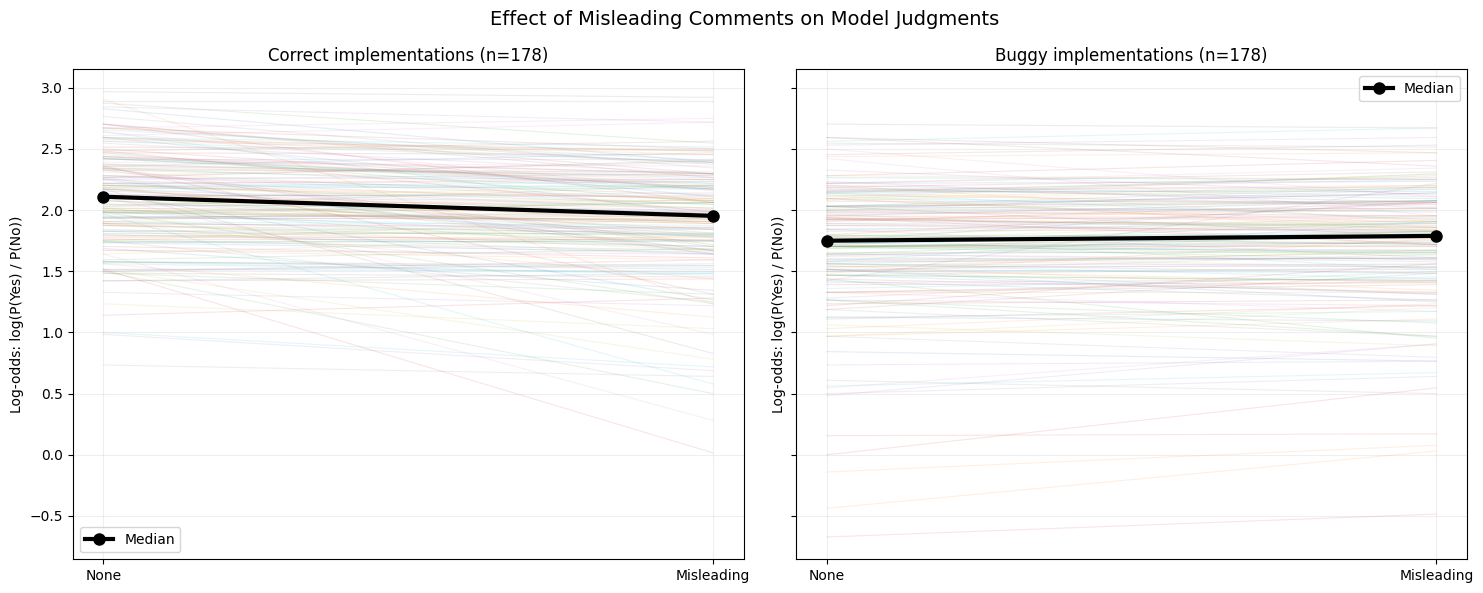

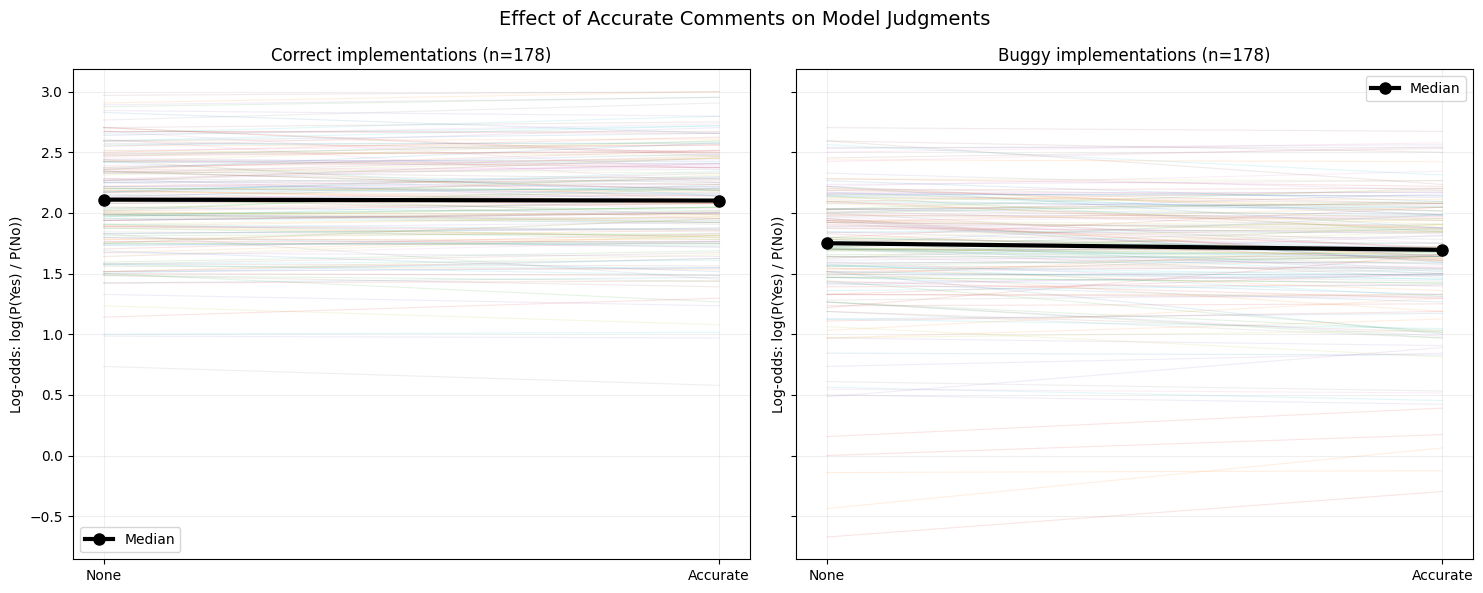


========== PAIRED WILCOXON TESTS ==========


,comparison,code_version,n,median_shift,p_value
0,none_to_misleading,correct,178,-0.093750,2.346079e-17
1,none_to_misleading,buggy,178,0.015625,5.147832e-01
2,none_to_accurate,correct,178,0.015625,9.997570e-02
3,none_to_accurate,buggy,178,-0.031250,1.188095e-04



========== EFFECT SIZE COMPARISON ==========

CORRECT CODE
Median misleading effect: -0.0938
Median accurate effect:   0.0156
Absolute misleading effect: 0.0938
Absolute accurate effect:   0.0156

BUGGY CODE
Median misleading effect: 0.0156
Median accurate effect:   -0.0313
Absolute misleading effect: 0.0156
Absolute accurate effect:   0.0313

Analysis completed.
Results saved to Google Drive: /content/drive/MyDrive/visualisation


In [ ]:
analysis_df = results_df.merge(
    inputs_df[
        ["problem_id", "code_version", "comment_type"]
    ],
    on=["problem_id", "code_version", "comment_type"],
    how="inner",
    validate="one_to_one"
)


EPS = 1e-7

analysis_df["p_yes"] = analysis_df["p_yes"].clip(
    EPS, 1 - EPS
)

analysis_df["p_no"] = analysis_df["p_no"].clip(
    EPS, 1 - EPS
)


analysis_df["log_odds"] = np.log(
    analysis_df["p_yes"] / analysis_df["p_no"]
)

print("Total observations:", len(analysis_df))
print("Problems:", analysis_df["problem_id"].nunique())



def prepare_comparison(target_condition):

    # Keep only none and the target condition
    subset = analysis_df[
        analysis_df["comment_type"].isin(
            ["none", target_condition]
        )
    ]

    # Pair rows by problem_id and code_version
    paired = subset.pivot(
        index=["problem_id", "code_version"],
        columns="comment_type",
        values="log_odds"
    ).reset_index()

    # Keep only complete pairs
    paired = paired.dropna(
        subset=["none", target_condition]
    )

    # Calculate shift: target condition minus none
    paired["shift"] = (
        paired[target_condition] - paired["none"]
    )

    return paired

def plot_slope(target_condition):

    paired = prepare_comparison(target_condition)

    fig, axes = plt.subplots(
        1, 2,
        figsize=(15, 6),
        sharey=True
    )

    for ax, version in zip(
        axes, ["correct", "buggy"]
    ):

        data = paired[
            paired["code_version"] == version
        ]


        for _, row in data.iterrows():

            ax.plot(
                [0, 1],
                [row["none"], row[target_condition]],
                alpha=0.12,
                linewidth=0.8
            )


        median_none = data["none"].median()
        median_target = data[target_condition].median()

        ax.plot(
            [0, 1],
            [median_none, median_target],
            color="black",
            linewidth=3,
            marker="o",
            markersize=8,
            label="Median"
        )

        ax.set_xticks([0, 1])
        ax.set_xticklabels([
            "None",
            target_condition.capitalize()
        ])

        ax.set_title(
            f"{version.capitalize()} implementations (n={len(data)})"
        )

        ax.set_ylabel("Log-odds: log(P(Yes) / P(No))")
        ax.grid(alpha=0.2)
        ax.legend()

    plt.suptitle(
        f"Effect of {target_condition.capitalize()} Comments on Model Judgments",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

    return paired

misleading_paired = plot_slope("misleading")

accurate_paired = plot_slope("accurate")

def calculate_statistics(paired, condition):

    results = []

    for version in ["correct", "buggy"]:

        data = paired[
            paired["code_version"] == version
        ]

        shifts = data["shift"].dropna()

        n = len(shifts)
        median_shift = shifts.median()

        if n == 0:
            p_value = np.nan

        elif np.allclose(shifts, 0):
            p_value = 1.0

        else:
            p_value = wilcoxon(
                shifts,
                alternative="two-sided"
            ).pvalue

        results.append({
            "comparison": f"none_to_{condition}",
            "code_version": version,
            "n": n,
            "median_shift": median_shift,
            "p_value": p_value
        })

    return results


statistics = []

statistics.extend(
    calculate_statistics(
        misleading_paired, "misleading"
    )
)

statistics.extend(
    calculate_statistics(
        accurate_paired, "accurate"
    )
)

stats_df = pd.DataFrame(statistics)

print("\n========== PAIRED WILCOXON TESTS ==========")
display(stats_df)

print("\n========== EFFECT SIZE COMPARISON ==========")

for version in ["correct", "buggy"]:

    misleading_shift = stats_df.loc[
        (stats_df["code_version"] == version) &
        (stats_df["comparison"] == "none_to_misleading"),
        "median_shift"
    ].iloc[0]

    accurate_shift = stats_df.loc[
        (stats_df["code_version"] == version) &
        (stats_df["comparison"] == "none_to_accurate"),
        "median_shift"
    ].iloc[0]

    print(f"\n{version.upper()} CODE")
    print(f"Median misleading effect: {misleading_shift:.4f}")
    print(f"Median accurate effect:   {accurate_shift:.4f}")
    print(
        f"Absolute misleading effect: {abs(misleading_shift):.4f}"
    )
    print(
        f"Absolute accurate effect:   {abs(accurate_shift):.4f}"
    )

OUTPUT_DIR = "/content/drive/MyDrive/visualisation"

misleading_paired.to_csv(
    f"{OUTPUT_DIR}/logodds_none_to_misleading.csv",
    index=False
)

accurate_paired.to_csv(
    f"{OUTPUT_DIR}/logodds_none_to_accurate.csv",
    index=False
)

stats_df.to_csv(
    f"{OUTPUT_DIR}/logodds_wilcoxon_results.csv",
    index=False
)

print("\nAnalysis completed.")
print("Results saved to Google Drive:", OUTPUT_DIR)

## 5. Question 3: do some bug types respond more strongly to comments?

Break the comment effects down by bug type. The analysis uses the correct, uncommented version of each problem as the baseline.

========== PROBLEMS PER BUG TYPE ==========


,number_of_problems
bug_type,
Eq_to_NotEq,30
Mult_to_Div,27
Add_to_Sub,21
Gt_to_Lt,19
Lt_to_Gt,17
Sub_to_Add,13
max_to_min,12
NotEq_to_Eq,8
LtE_to_GtE,8



Problems without baseline: 0

========== MEAN LOG-ODDS SHIFT ==========


condition,correct | none,correct | accurate,correct | misleading,buggy | none,buggy | accurate,buggy | misleading
bug_type,,,,,,
Add_to_Sub,0.0,-0.0260,-0.1548,-0.4807,-0.4829,-0.4769
And_to_Or,0.0,-0.1094,-0.2891,-0.0156,-0.2500,-0.1172
Div_to_Mult,0.0,-0.2031,0.1250,-0.2135,-0.0521,-0.5313
Eq_to_NotEq,0.0,0.0089,-0.0969,-0.4432,-0.4875,-0.4547
FloorDiv_to_Div,0.0,0.1562,-0.2500,-1.1250,-1.0625,-0.3281
GtE_to_LtE,0.0,0.0268,-0.0335,-0.6094,-0.5737,-0.5536
Gt_to_Lt,0.0,-0.0074,-0.0354,-0.1785,-0.1785,-0.1859
LtE_to_GtE,0.0,0.0410,0.0176,-0.2246,-0.1504,-0.1465
Lt_to_Gt,0.0,0.0083,-0.0230,-0.2491,-0.2316,-0.2546



========== NUMBER OF PROBLEMS PER CELL ==========


condition,correct | none,correct | accurate,correct | misleading,buggy | none,buggy | accurate,buggy | misleading
bug_type,,,,,,
Add_to_Sub,21,21,21,21,21,21
And_to_Or,2,2,2,2,2,2
Div_to_Mult,3,3,3,3,3,3
Eq_to_NotEq,30,30,30,30,30,30
FloorDiv_to_Div,1,1,1,1,1,1
GtE_to_LtE,7,7,7,7,7,7
Gt_to_Lt,19,19,19,19,19,19
LtE_to_GtE,8,8,8,8,8,8
Lt_to_Gt,17,17,17,17,17,17


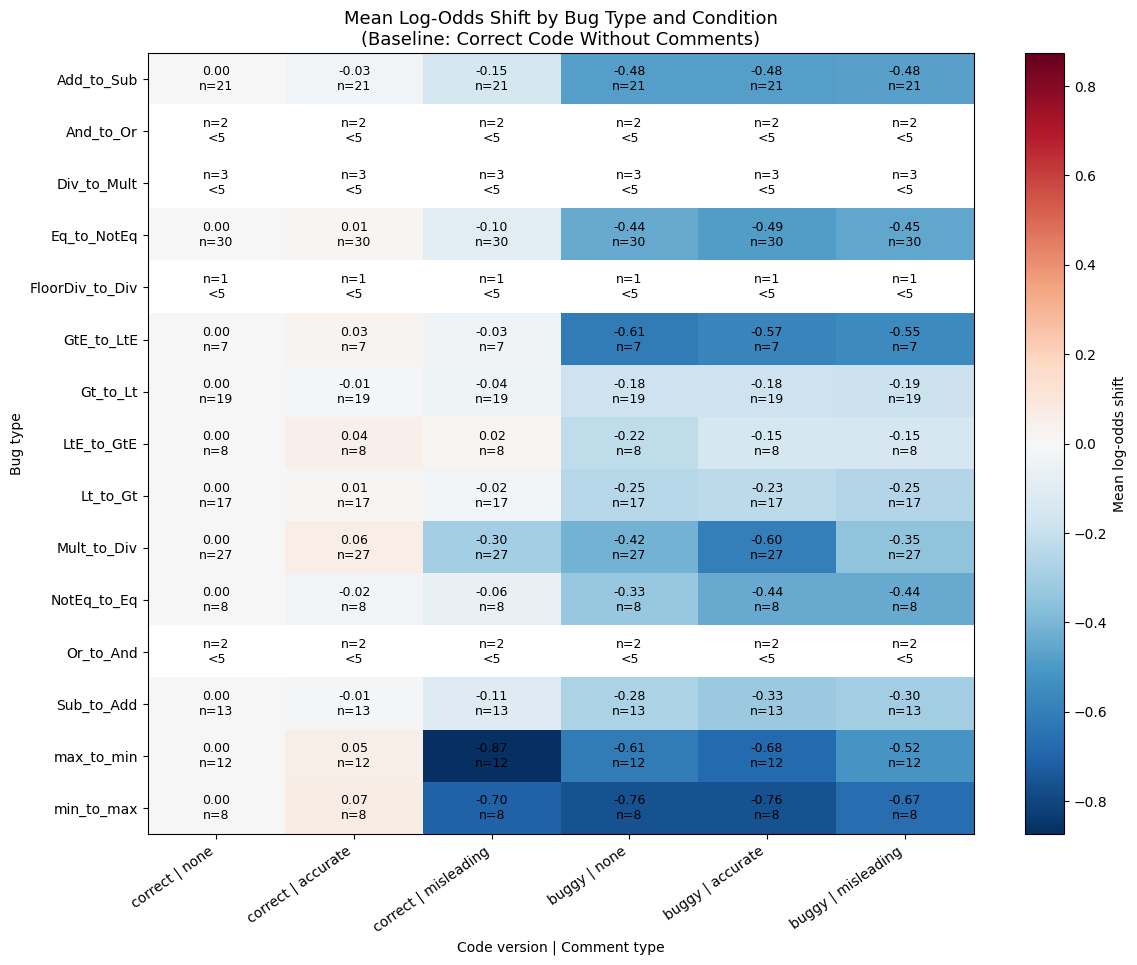


========== MAX/MIN BUG TYPE ANALYSIS ==========


,bug_type,condition,mean_shift,median_shift,n,std
78,max_to_min,buggy | accurate,-0.6823,-0.5859,12,0.4449
79,max_to_min,buggy | misleading,-0.5182,-0.3906,12,0.3757
80,max_to_min,buggy | none,-0.6120,-0.4453,12,0.4815
81,max_to_min,correct | accurate,0.0534,0.0938,12,0.1317
82,max_to_min,correct | misleading,-0.8737,-0.9375,12,0.4829
83,max_to_min,correct | none,0.0000,0.0000,12,0.0000
84,min_to_max,buggy | accurate,-0.7598,-0.4688,8,0.8706
85,min_to_max,buggy | misleading,-0.6680,-0.3437,8,0.9123
86,min_to_max,buggy | none,-0.7598,-0.4922,8,1.0614
87,min_to_max,correct | accurate,0.0664,0.0938,8,0.1157



========== COMPARISON WITH OTHER BUG TYPES ==========

MAX_TO_MIN
buggy | accurate: mean=-0.6823, median=-0.5859, n=12, other bug types mean=-0.4039
buggy | misleading: mean=-0.5182, median=-0.3906, n=12, other bug types mean=-0.3583
buggy | none: mean=-0.6120, median=-0.4453, n=12, other bug types mean=-0.3705
correct | accurate: mean=0.0534, median=0.0938, n=12, other bug types mean=-0.0306
correct | misleading: mean=-0.8737, median=-0.9375, n=12, other bug types mean=-0.1100
correct | none: mean=0.0000, median=0.0000, n=12, other bug types mean=0.0000

MIN_TO_MAX
buggy | accurate: mean=-0.7598, median=-0.4688, n=8, other bug types mean=-0.4039
buggy | misleading: mean=-0.6680, median=-0.3437, n=8, other bug types mean=-0.3583
buggy | none: mean=-0.7598, median=-0.4922, n=8, other bug types mean=-0.3705
correct | accurate: mean=0.0664, median=0.0938, n=8, other bug types mean=-0.0306
correct | misleading: mean=-0.7031, median=-0.6641, n=8, other bug types mean=-0.1100
correct | none

In [ ]:
merge_cols = ["problem_id", "code_version", "comment_type"]

analysis_df = results_df.drop(
    columns=["bug_type"], errors="ignore"
).merge(
    inputs_df[merge_cols + ["bug_type"]],
    on=merge_cols,
    how="inner",
    validate="one_to_one"
)

EPS = 1e-7

analysis_df["p_yes"] = analysis_df["p_yes"].clip(
    EPS, 1 - EPS
)

analysis_df["p_no"] = analysis_df["p_no"].clip(
    EPS, 1 - EPS
)

analysis_df["log_odds"] = np.log(
    analysis_df["p_yes"] / analysis_df["p_no"]
)

bug_counts = (
    analysis_df[
        analysis_df["code_version"] == "buggy"
    ]
    .groupby("bug_type")["problem_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("========== PROBLEMS PER BUG TYPE ==========")
display(
    bug_counts.rename("number_of_problems").to_frame()
)

bug_type_per_problem = (
    analysis_df[
        analysis_df["code_version"] == "buggy"
    ]
    .groupby("problem_id")["bug_type"]
    .nunique()
)

assert (bug_type_per_problem == 1).all(), (
    "Some problems have multiple bug types!"
)

baseline = analysis_df[
    (analysis_df["code_version"] == "correct") &
    (analysis_df["comment_type"] == "none")
][["problem_id", "log_odds"]].rename(
    columns={"log_odds": "baseline_log_odds"}
)

assert not baseline["problem_id"].duplicated().any()

analysis_df = analysis_df.merge(
    baseline,
    on="problem_id",
    how="left",
    validate="many_to_one"
)

print("\nProblems without baseline:",
      analysis_df["baseline_log_odds"].isna().sum())


analysis_df["log_odds_shift"] = (
    analysis_df["log_odds"] -
    analysis_df["baseline_log_odds"]
)

analysis_df = analysis_df.dropna(
    subset=["log_odds_shift", "bug_type"]
)

analysis_df["condition"] = (
    analysis_df["code_version"].astype(str) +
    " | " +
    analysis_df["comment_type"].astype(str)
)

condition_order = [
    "correct | none",
    "correct | accurate",
    "correct | misleading",
    "buggy | none",
    "buggy | accurate",
    "buggy | misleading"
]

condition_order = [
    c for c in condition_order
    if c in analysis_df["condition"].unique()
]

summary = (
    analysis_df
    .groupby(["bug_type", "condition"])
    .agg(
        mean_shift=("log_odds_shift", "mean"),
        median_shift=("log_odds_shift", "median"),
        n=("problem_id", "nunique"),
        std=("log_odds_shift", "std")
    )
    .reset_index()
)

mean_matrix = summary.pivot(
    index="bug_type",
    columns="condition",
    values="mean_shift"
).reindex(columns=condition_order)

count_matrix = summary.pivot(
    index="bug_type",
    columns="condition",
    values="n"
).reindex(columns=condition_order)

median_matrix = summary.pivot(
    index="bug_type",
    columns="condition",
    values="median_shift"
).reindex(columns=condition_order)

print("\n========== MEAN LOG-ODDS SHIFT ==========")
display(mean_matrix.round(4))

print("\n========== NUMBER OF PROBLEMS PER CELL ==========")
display(count_matrix.fillna(0).astype(int))

MIN_N = 5

plot_matrix = mean_matrix.copy()

mask = (
    count_matrix.isna() |
    (count_matrix < MIN_N) |
    plot_matrix.isna()
)

fig, ax = plt.subplots(
    figsize=(
        max(12, len(condition_order) * 2),
        max(6, len(mean_matrix) * 0.65)
    )
)

data = np.ma.masked_where(
    mask.values,
    plot_matrix.values
)

valid_values = plot_matrix.values[~mask.values]

if len(valid_values) > 0:
    limit = max(abs(valid_values).max(), 0.01)
else:
    limit = 1

im = ax.imshow(
    data,
    cmap="RdBu_r",
    aspect="auto",
    vmin=-limit,
    vmax=limit
)

for i in range(len(mean_matrix.index)):
    for j in range(len(mean_matrix.columns)):

        n = count_matrix.iloc[i, j]
        value = mean_matrix.iloc[i, j]

        if pd.isna(n) or pd.isna(value):
            label = "No data"

        elif n < MIN_N:
            label = f"n={int(n)}\n<5"

        else:
            label = f"{value:.2f}\nn={int(n)}"

        ax.text(
            j, i,
            label,
            ha="center",
            va="center",
            fontsize=9,
            color="black"
        )

ax.set_xticks(range(len(mean_matrix.columns)))
ax.set_xticklabels(
    mean_matrix.columns,
    rotation=35,
    ha="right"
)

ax.set_yticks(range(len(mean_matrix.index)))
ax.set_yticklabels(mean_matrix.index)

ax.set_title(
    "Mean Log-Odds Shift by Bug Type and Condition\n"
    "(Baseline: Correct Code Without Comments)",
    fontsize=13
)

ax.set_xlabel("Code version | Comment type")
ax.set_ylabel("Bug type")

plt.colorbar(
    im,
    ax=ax,
    label="Mean log-odds shift"
)

plt.tight_layout()
plt.show()

extreme_types = ["max_to_min", "min_to_max"]

extreme_summary = summary[
    summary["bug_type"].isin(extreme_types)
].copy()

print("\n========== MAX/MIN BUG TYPE ANALYSIS ==========")

if extreme_summary.empty:
    print("max_to_min / min_to_max not found.")
    print("Available bug types:", analysis_df["bug_type"].unique())

else:
    display(
        extreme_summary.sort_values(
            ["bug_type", "condition"]
        ).round(4)
    )

other_summary = summary[
    ~summary["bug_type"].isin(extreme_types)
]

print("\n========== COMPARISON WITH OTHER BUG TYPES ==========")

for bug in extreme_types:

    bug_data = summary[
        summary["bug_type"] == bug
    ]

    if bug_data.empty:
        continue

    print(f"\n{bug.upper()}")

    for _, row in bug_data.iterrows():

        other = other_summary[
            other_summary["condition"] == row["condition"]
        ]

        other_mean = other["mean_shift"].mean()

        print(
            f"{row['condition']}: "
            f"mean={row['mean_shift']:.4f}, "
            f"median={row['median_shift']:.4f}, "
            f"n={row['n']}, "
            f"other bug types mean={other_mean:.4f}"
        )

OUTPUT_DIR = "/content/drive/MyDrive/visualisation"

summary.to_csv(
    f"{OUTPUT_DIR}/bug_type_logodds_summary.csv",
    index=False
)

mean_matrix.to_csv(
    f"{OUTPUT_DIR}/bug_type_mean_logodds_heatmap.csv"
)

count_matrix.to_csv(
    f"{OUTPUT_DIR}/bug_type_sample_counts.csv"
)

analysis_df.to_csv(
    f"{OUTPUT_DIR}/bug_type_logodds_data.csv",
    index=False
)

print("\nAnalysis completed.")
print("Results saved to:", OUTPUT_DIR)

## 6. Control experiment: does the comment's meaning matter, or does its presence matter?

The earlier comparison cannot separate the effect of a comment's meaning from the effect of simply having a comment. This control adds a neutral comment that does not describe the code, while keeping the code itself unchanged.

In [ ]:
def get_comment_tokens(code):
    return [
        tok for tok in tokenize.generate_tokens(
            io.StringIO(code).readline
        )
        if tok.type == tokenize.COMMENT
    ]


def get_ast(code):
    return ast.dump(
        ast.parse(code),
        include_attributes=False
    )


def make_neutral_comment(target_length):
    if target_length < 3:
        raise ValueError("Original comment is too short to replace.")

    prefix = "# "
    remaining = target_length - len(prefix)

    neutral_text = "General note: no behaviour is described."

    while len(neutral_text) < remaining:
        neutral_text += " General note."

    neutral_text = neutral_text[:remaining]

    return prefix + neutral_text


def replace_comment(code, comment_token):
    lines = code.splitlines(keepends=True)

    line_number, column = comment_token.start
    old_token = comment_token.string

    new_token = make_neutral_comment(len(old_token))

    line = lines[line_number - 1]

    lines[line_number - 1] = (
        line[:column]
        + new_token
        + line[column + len(old_token):]
    )

    return "".join(lines), new_token


neutral_input_rows = []
validation_records = []

group_cols = ["problem_id", "code_version"]

for (problem_id, code_version), group in tqdm(
    inputs_df.groupby(group_cols),
    desc="Creating neutral comments"
):

    none_row = group[group["comment_type"] == "none"]
    accurate_row = group[group["comment_type"] == "accurate"]
    misleading_row = group[group["comment_type"] == "misleading"]

    assert len(none_row) == 1
    assert len(accurate_row) == 1
    assert len(misleading_row) == 1

    none_row = none_row.iloc[0]
    accurate_row = accurate_row.iloc[0]
    misleading_row = misleading_row.iloc[0]

    original_code = none_row["code"]
    accurate_code = accurate_row["code"]
    misleading_code = misleading_row["code"]

    accurate_comments = get_comment_tokens(accurate_code)
    misleading_comments = get_comment_tokens(misleading_code)

    assert len(accurate_comments) == 1, (
        f"Expected one accurate comment: {problem_id}, {code_version}"
    )

    assert len(misleading_comments) == 1, (
        f"Expected one misleading comment: {problem_id}, {code_version}"
    )

    accurate_comment = accurate_comments[0]
    misleading_comment = misleading_comments[0]

    same_position = (
        accurate_comment.start == misleading_comment.start
    )

    original_ast = get_ast(original_code)

    neutral_code, neutral_comment = replace_comment(
        accurate_code,
        accurate_comment
    )

    assert len(neutral_comment) == len(accurate_comment.string)

    neutral_comments = get_comment_tokens(neutral_code)

    assert len(neutral_comments) == 1
    assert neutral_comments[0].start == accurate_comment.start

    assert get_ast(neutral_code) == original_ast, (
        f"Neutral AST differs from original: {problem_id}, {code_version}"
    )

    new_row = none_row.copy()
    new_row["comment_type"] = "neutral"
    new_row["code"] = neutral_code
    new_row["code_length"] = len(neutral_code)

    neutral_input_rows.append(new_row)

    validation_records.append({
        "problem_id": problem_id,
        "code_version": code_version,
        "comment_position": accurate_comment.start,
        "accurate_length": len(accurate_comment.string),
        "misleading_length": len(misleading_comment.string),
        "neutral_length": len(neutral_comment),
        "same_comment_position": same_position,
        "ast_identical": True
    })


neutral_inputs_df = pd.DataFrame(neutral_input_rows)
validation_df = pd.DataFrame(validation_records)

print("\nNeutral input generation completed.")
print("New rows:", len(neutral_inputs_df))
print("Unique problems:", neutral_inputs_df["problem_id"].nunique())
print("\nValidation summary:")
display(
    validation_df.groupby(
        ["same_comment_position", "ast_identical"]
    ).size().reset_index(name="count")
)

print("\nComment length comparison:")
display(
    validation_df[
        [
            "accurate_length",
            "misleading_length",
            "neutral_length"
        ]
    ].describe()
)

validation_df.to_csv(
    "/content/drive/MyDrive/visualisation/neutral_validation.csv",
    index=False
)

neutral_results = []

for _, row in tqdm(
    neutral_inputs_df.iterrows(),
    total=len(neutral_inputs_df),
    desc="Scoring neutral implementations"
):

    scores = score_row(row)

    neutral_results.append({
        "problem_id": row["problem_id"],
        "code_version": row["code_version"],
        "comment_type": "neutral",
        "bug_type": row.get("bug_type", None),
        "code_length": row["code_length"],
        "p_yes": scores["p_yes"],
        "p_no": scores["p_no"]
    })


neutral_results_df = pd.DataFrame(neutral_results)

inputs_df = inputs_df[
    inputs_df["comment_type"] != "neutral"
].copy()

results_df = results_df[
    results_df["comment_type"] != "neutral"
].copy()

inputs_df = pd.concat(
    [inputs_df, neutral_inputs_df],
    ignore_index=True
)

results_df = pd.concat(
    [results_df, neutral_results_df],
    ignore_index=True
)

folder = "/content/drive/MyDrive/visualisation"

inputs_df.to_csv(
    f"{folder}/inputs_with_neutral.csv",
    index=False
)

results_df.to_csv(
    f"{folder}/results_with_neutral.csv",
    index=False
)

print("\nScoring completed.")
print("Updated input rows:", len(inputs_df))
print("Updated result rows:", len(results_df))

print("\nCondition counts:")
print(results_df["comment_type"].value_counts())

Creating neutral comments:   0%|          | 0/356 [00:00<?, ?it/s]


Neutral input generation completed.
New rows: 356
Unique problems: 178

Validation summary:


,same_comment_position,ast_identical,count
0,True,True,356



Comment length comparison:


,accurate_length,misleading_length,neutral_length
count,356.000000,356.000000,356.000000
mean,36.719101,36.719101,36.719101
std,8.774789,8.774789,8.774789
min,22.000000,22.000000,22.000000
25%,28.000000,28.000000,28.000000
50%,40.500000,40.500000,40.500000
75%,43.000000,43.000000,43.000000
max,52.000000,52.000000,52.000000


Scoring neutral implementations:   0%|          | 0/356 [00:00<?, ?it/s]


Scoring completed.
Updated input rows: 1424
Updated result rows: 1424

Condition counts:
comment_type
none          356
accurate      356
misleading    356
neutral       356
Name: count, dtype: int64


Paired log-odds shifts relative to no comment:


,code_version,condition,n,mean_shift,median_shift,p_value
0,correct,neutral,178,-0.750966,-0.695312,5.821360e-31
1,correct,accurate,178,0.007110,0.015625,9.997570e-02
2,correct,misleading,178,-0.192416,-0.093750,2.346079e-17
3,buggy,neutral,178,-0.715941,-0.656250,6.229145e-31
4,buggy,accurate,178,-0.043890,-0.031250,1.188095e-04
5,buggy,misleading,178,0.010973,0.015625,5.147832e-01


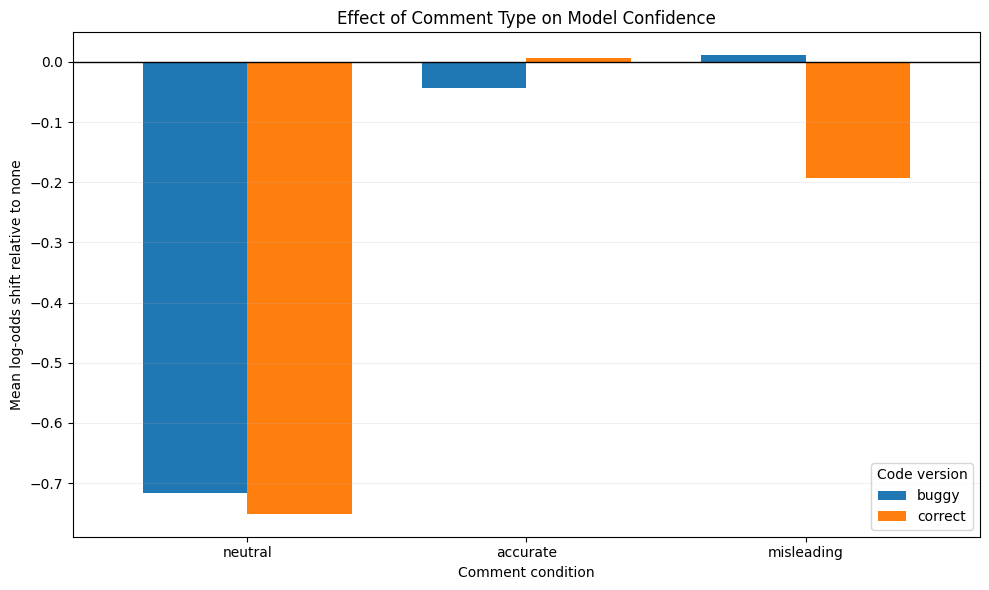


Neutral vs misleading comparison:

CORRECT code
Neutral mean shift:    -0.751
Misleading mean shift: -0.1924
Difference (neutral - misleading): -0.5585

BUGGY code
Neutral mean shift:    -0.7159
Misleading mean shift: 0.011
Difference (neutral - misleading): -0.7269

Comparison completed.


In [ ]:
EPS = 1e-7

comparison_df = results_df.copy()

comparison_df["log_odds"] = np.log(
    comparison_df["p_yes"].clip(EPS, 1 - EPS) /
    comparison_df["p_no"].clip(EPS, 1 - EPS)
)

conditions = ["none", "neutral", "accurate", "misleading"]

pair_cols = ["problem_id", "code_version"]

wide_df = comparison_df.pivot(
    index=pair_cols,
    columns="comment_type",
    values="log_odds"
).reset_index()

comparison_rows = []

for code_version in ["correct", "buggy"]:

    subset = wide_df[
        wide_df["code_version"] == code_version
    ].copy()

    for condition in ["neutral", "accurate", "misleading"]:

        valid = subset[["none", condition]].dropna()

        shifts = valid[condition] - valid["none"]

        if len(shifts) == 0:
            continue

        if np.allclose(shifts, 0):
            p_value = 1.0
        else:
            p_value = wilcoxon(
                shifts,
                alternative="two-sided"
            ).pvalue

        comparison_rows.append({
            "code_version": code_version,
            "condition": condition,
            "n": len(shifts),
            "mean_shift": shifts.mean(),
            "median_shift": shifts.median(),
            "p_value": p_value
        })

comparison_stats = pd.DataFrame(comparison_rows)

print("Paired log-odds shifts relative to no comment:")
display(comparison_stats)

plot_df = (
    comparison_stats
    .pivot(
        index="condition",
        columns="code_version",
        values="mean_shift"
    )
    .reindex(["neutral", "accurate", "misleading"])
)

ax = plot_df.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Mean log-odds shift relative to none")
ax.set_xlabel("Comment condition")
ax.set_title("Effect of Comment Type on Model Confidence")
ax.legend(title="Code version")
ax.grid(axis="y", alpha=0.2)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nNeutral vs misleading comparison:")

for code_version in ["correct", "buggy"]:

    subset = wide_df[
        wide_df["code_version"] == code_version
    ].dropna(subset=["neutral", "misleading"])

    neutral_shift = subset["neutral"] - subset["none"]
    misleading_shift = subset["misleading"] - subset["none"]

    print(f"\n{code_version.upper()} code")
    print("Neutral mean shift:   ", round(neutral_shift.mean(), 4))
    print("Misleading mean shift:", round(misleading_shift.mean(), 4))
    print(
        "Difference (neutral - misleading):",
        round((neutral_shift - misleading_shift).mean(), 4)
    )

folder = "/content/drive/MyDrive/visualisation"

comparison_stats.to_csv(
    f"{folder}/neutral_condition_comparison.csv",
    index=False
)

wide_df.to_csv(
    f"{folder}/neutral_condition_paired_logodds.csv",
    index=False
)

print("\nComparison completed.")

## 7. Follow-up: why do the strongest cases react?


Number of paired problem/code-version observations: 356
Number of unique problems: 178

========== 10 LARGEST DIFFERENCES ==========


,ranking,problem_id,code_version,neutral_shift,misleading_shift,difference,p_yes_none,code_chars_neutral,operator_count_neutral,comment_neutral,comment_misleading,comment_position_neutral,lexical_matches_misleading,lexical_overlap_misleading
0,Largest difference,299,correct,-0.781250,-1.390625,0.609375,0.877477,230,1,General note: no behaviour,Selects the minimum value.,"line 7, col 50",,0.0
1,Largest difference,130,correct,-0.515625,-1.046875,0.531250,0.913677,234,1,General note: no behaviour,Selects the minimum value.,"line 7, col 52",,0.0
2,Largest difference,120,correct,-0.859375,-1.343750,0.484375,0.897695,135,1,General note: no behaviour,Selects the minimum value.,"line 2, col 54",,0.0
3,Largest difference,418,correct,-1.046875,-1.500000,0.453125,0.819893,104,0,General note: no behaviour,Selects the minimum value.,"line 2, col 37",,0.0
4,Largest difference,294,correct,-1.000000,-1.359375,0.359375,0.837620,133,0,General note: no behaviour,Selects the minimum value.,"line 2, col 63",,0.0
5,Largest difference,393,correct,-0.593750,-0.875000,0.281250,0.894789,201,0,General note: no behaviour,Selects the minimum value.,"line 2, col 52",,0.0
6,Largest difference,457,correct,-1.062500,-1.125000,0.062500,0.891811,78,0,General note: no behaviour,Selects the maximum value.,"line 2, col 30",,0.0
7,Largest difference,62,correct,-1.609375,-1.671875,0.062500,0.948155,71,0,General note: no behaviour,Selects the maximum value.,"line 2, col 20",,0.0
8,Largest difference,94,correct,-0.625000,-0.625000,0.000000,0.911180,155,0,General note: no behaviour,Selects the maximum value.,"line 4, col 48",,0.0
9,Largest difference,167,correct,-0.140625,-0.140625,0.000000,0.888759,197,8,General note: no behaviour is des,Requires at least one condition to hold.,"line 2, col 31",,0.0



========== 10 SMALLEST DIFFERENCES ==========


,ranking,problem_id,code_version,neutral_shift,misleading_shift,difference,p_yes_none,code_chars_neutral,operator_count_neutral,comment_neutral,comment_misleading,comment_position_neutral,lexical_matches_misleading,lexical_overlap_misleading
0,Smallest difference,292,buggy,-1.171875,0.796875,-1.968750,0.805632,73,1,General note: no behaviour,Performs floor division.,"line 2, col 15",,0.0
1,Smallest difference,14,buggy,-1.937500,-0.015625,-1.921875,0.855851,81,3,General note: no behaviour,Multiplies the two values.,"line 2, col 26",,0.0
2,Smallest difference,14,correct,-1.906250,-0.109375,-1.796875,0.880797,81,3,General note: no behaviour,Performs regular division.,"line 2, col 26",,0.0
3,Smallest difference,458,buggy,-1.562500,0.187500,-1.750000,0.891811,89,1,General note: no behaviour,Multiplies the two values.,"line 2, col 18",,0.0
4,Smallest difference,274,buggy,-1.796875,-0.109375,-1.687500,0.819893,91,2,General note: no beh,Subtracts the right value from the left.,"line 4, col 23",,0.0
5,Smallest difference,171,correct,-1.781250,-0.140625,-1.640625,0.930458,113,1,General note: no behaviour,Performs regular division.,"line 4, col 23",,0.0
6,Smallest difference,135,buggy,-1.546875,0.093750,-1.640625,0.901921,79,3,General note: no behaviour,Multiplies the two values.,"line 2, col 28",,0.0
7,Smallest difference,234,buggy,-1.484375,0.125000,-1.609375,0.875787,91,2,General note: no behaviour,Multiplies the two values.,"line 2, col 24",,0.0
8,Smallest difference,171,buggy,-1.500000,0.093750,-1.593750,0.872347,113,1,General note: no behaviour,Multiplies the two values.,"line 4, col 23",,0.0
9,Smallest difference,276,buggy,-1.421875,0.140625,-1.562500,0.894789,107,3,General note: no behaviour,Multiplies the two values.,"line 2, col 33",,0.0



========== MANUAL CODE INSPECTION ==========

Largest difference | Problem 299 | correct
Difference: 0.6094 | Neutral shift: -0.7812 | Misleading shift: -1.3906

Baseline P(Yes): 0.8775

NEUTRAL COMMENT:
General note: no behaviour

MISLEADING COMMENT:
Selects the minimum value.

NEUTRAL CODE:
from collections import defaultdict

def max_aggregate(stdata):
    temp = defaultdict(int)
    for name, marks in stdata:
        temp[name] += marks
    return max(temp.items(), key=lambda x: x[1])  # General note: no behaviour


MISLEADING CODE:
from collections import defaultdict

def max_aggregate(stdata):
    temp = defaultdict(int)
    for name, marks in stdata:
        temp[name] += marks
    return max(temp.items(), key=lambda x: x[1])  # Selects the minimum value.


Largest difference | Problem 130 | correct
Difference: 0.5312 | Neutral shift: -0.5156 | Misleading shift: -1.0469

Baseline P(Yes): 0.9137

NEUTRAL COMMENT:
General note: no behaviour

MISLEADING COMMENT:
Selects the minimu

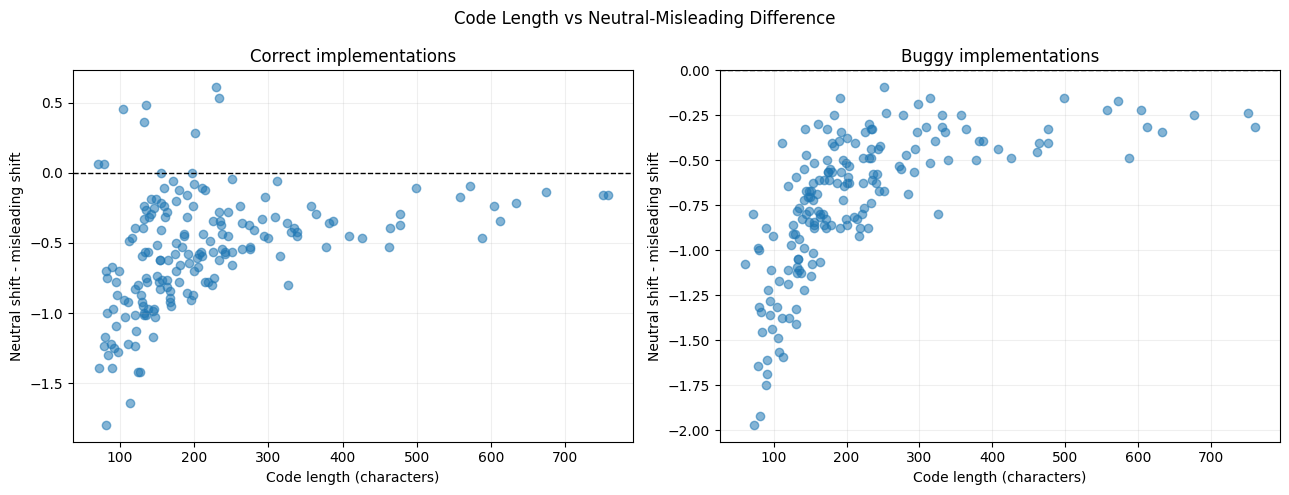


Spearman correlation: code length vs difference
correct : n=178, rho=0.5054, p=6.2388e-13
buggy   : n=178, rho=0.7905, p=2.5017e-39


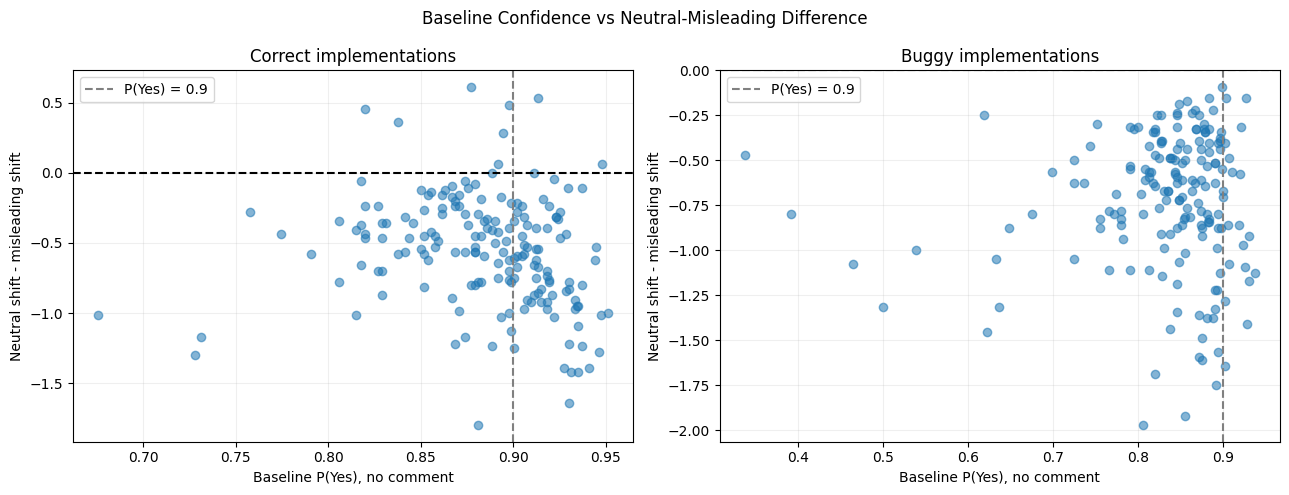


Baseline P(Yes) summary:


,count,mean,median,min,max
code_version,,,,,
buggy,178,0.832946,0.851953,0.338077,0.937211
correct,178,0.883739,0.891811,0.675765,0.951142



Difference by baseline confidence:


,code_version,baseline_ceiling,count,mean,median,std
0,buggy,False,158,-0.714893,-0.625000,0.381812
1,buggy,True,20,-0.821875,-0.859375,0.410823
2,correct,False,104,-0.470553,-0.453125,0.383718
3,correct,True,74,-0.682221,-0.687500,0.399353



Lexical overlap summary:


,count,mean,median,min,max
code_version,,,,,
buggy,178,0.006599,0.0,0.0,0.166667
correct,178,0.005663,0.0,0.0,0.166667


... (9 outputs left out)

,code_version,comment_position_neutral,count,mean,median
0,buggy,"line 11, col 25",1,-0.343750,-0.343750
1,buggy,"line 12, col 18",1,-0.312500,-0.312500
2,buggy,"line 14, col 57",1,-0.156250,-0.156250
3,buggy,"line 15, col 32",1,-0.171875,-0.171875
4,buggy,"line 19, col 16",1,-0.218750,-0.218750
...,...,...,...,...,...
239,correct,"line 7, col 52",1,0.531250,0.531250
240,correct,"line 7, col 99",1,-0.234375,-0.234375
241,correct,"line 8, col 27",1,-0.453125,-0.453125
242,correct,"line 9, col 37",1,-0.390625,-0.390625



Paired Wilcoxon tests: neutral shift vs misleading shift
CORRECT: n=178, median difference=-0.5391, mean difference=-0.5585, p=1.38247e-27
BUGGY: n=178, median difference=-0.6562, mean difference=-0.7269, p=5.82115e-31

Most influential problems:


,problem_id,problem_mean_difference,absolute_influence
1,14,-1.859375,1.859375
114,292,-1.679688,1.679688
71,171,-1.617188,1.617188
167,458,-1.570312,1.570312
101,274,-1.453125,1.453125
55,135,-1.437500,1.437500
104,279,-1.375000,1.375000
2,17,-1.359375,1.359375
115,293,-1.304688,1.304688
102,276,-1.296875,1.296875



========== EXCLUDING TOP 0 INFLUENTIAL PROBLEMS ==========
CORRECT: n=178, mean neutral shift=-0.7510, mean misleading shift=-0.1924, mean difference=-0.5585
BUGGY: n=178, mean neutral shift=-0.7159, mean misleading shift=0.0110, mean difference=-0.7269
Overall mean difference: -0.6427

========== EXCLUDING TOP 2 INFLUENTIAL PROBLEMS ==========
CORRECT: n=176, mean neutral shift=-0.7393, mean misleading shift=-0.1926, mean difference=-0.5468
BUGGY: n=176, mean neutral shift=-0.7064, mean misleading shift=0.0067, mean difference=-0.7131
Overall mean difference: -0.6299

========== EXCLUDING TOP 3 INFLUENTIAL PROBLEMS ==========
CORRECT: n=175, mean neutral shift=-0.7334, mean misleading shift=-0.1929, mean difference=-0.5405
BUGGY: n=175, mean neutral shift=-0.7019, mean misleading shift=0.0062, mean difference=-0.7080
Overall mean difference: -0.6243

Investigation completed. CSV files saved to: /content/drive/MyDrive/visualisation


In [ ]:
folder = "/content/drive/MyDrive/visualisation"
EPS = 1e-7

merge_cols = ["problem_id", "code_version", "comment_type"]
input_cols = merge_cols + ["code", "specification"]

analysis = results_df.merge(
    inputs_df[input_cols],
    on=merge_cols,
    how="inner",
    validate="one_to_one"
)

analysis["log_odds"] = np.log(
    analysis["p_yes"].clip(EPS, 1 - EPS) /
    analysis["p_no"].clip(EPS, 1 - EPS)
)

wide = analysis.pivot(
    index=["problem_id", "code_version"],
    columns="comment_type",
    values=["log_odds", "p_yes"]
)

wide.columns = [
    f"{metric}_{condition}"
    for metric, condition in wide.columns
]

wide = wide.reset_index()

required = [
    "log_odds_none",
    "log_odds_neutral",
    "log_odds_misleading",
    "p_yes_none"
]

wide = wide.dropna(subset=required).copy()

wide["neutral_shift"] = (
    wide["log_odds_neutral"] - wide["log_odds_none"]
)

wide["misleading_shift"] = (
    wide["log_odds_misleading"] - wide["log_odds_none"]
)

wide["difference"] = (
    wide["neutral_shift"] - wide["misleading_shift"]
)

print("Number of paired problem/code-version observations:", len(wide))
print("Number of unique problems:", wide["problem_id"].nunique())

def extract_comments(code):
    try:
        return [
            tok for tok in tokenize.generate_tokens(
                io.StringIO(code).readline
            )
            if tok.type == tokenize.COMMENT
        ]
    except (tokenize.TokenError, IndentationError):
        return []


def extract_code_features(code):
    comments = extract_comments(code)

    comment_text = " | ".join(
        tok.string[1:].strip() for tok in comments
    )

    comment_positions = [
        f"line {tok.start[0]}, col {tok.start[1]}"
        for tok in comments
    ]

    try:
        tree = ast.parse(code)

        operator_count = sum(
            isinstance(node, (
                ast.Add, ast.Sub, ast.Mult, ast.Div, ast.FloorDiv,
                ast.Mod, ast.Pow, ast.Eq, ast.NotEq, ast.Lt,
                ast.LtE, ast.Gt, ast.GtE, ast.Is, ast.IsNot,
                ast.In, ast.NotIn, ast.And, ast.Or, ast.Not,
                ast.BitAnd, ast.BitOr, ast.BitXor, ast.LShift,
                ast.RShift, ast.UAdd, ast.USub
            ))
            for node in ast.walk(tree)
        )

        function_count = sum(
            isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
            for node in ast.walk(tree)
        )

    except SyntaxError:
        operator_count = np.nan
        function_count = np.nan

    code_without_comments = tokenize.untokenize([
        tok for tok in tokenize.generate_tokens(
            io.StringIO(code).readline
        )
        if tok.type != tokenize.COMMENT
    ])

    comment_words = set(
        re.findall(r"[a-zA-Z_][a-zA-Z_0-9]*", comment_text.lower())
    )

    code_words = set(
        re.findall(
            r"[a-zA-Z_][a-zA-Z_0-9]*",
            code_without_comments.lower()
        )
    )

    lexical_matches = sorted(comment_words & code_words)

    lexical_overlap = (
        len(lexical_matches) / len(comment_words)
        if comment_words else np.nan
    )

    return {
        "comment": comment_text,
        "comment_position": "; ".join(comment_positions),
        "comment_length": sum(len(tok.string) for tok in comments),
        "code_chars": len(code),
        "code_lines": len(code.splitlines()),
        "operator_count": operator_count,
        "function_count": function_count,
        "lexical_matches": ", ".join(lexical_matches),
        "lexical_overlap": lexical_overlap
    }


feature_rows = []

for _, row in analysis.iterrows():
    features = extract_code_features(row["code"])

    feature_rows.append({
        "problem_id": row["problem_id"],
        "code_version": row["code_version"],
        "comment_type": row["comment_type"],
        **features
    })

features_df = pd.DataFrame(feature_rows)

neutral_features = features_df[
    features_df["comment_type"] == "neutral"
].drop(columns="comment_type")

misleading_features = features_df[
    features_df["comment_type"] == "misleading"
].drop(columns="comment_type")

neutral_features = neutral_features.add_suffix("_neutral")
neutral_features = neutral_features.rename_axis(None, axis=1)

misleading_features = misleading_features.add_suffix("_misleading")
misleading_features = misleading_features.rename_axis(None, axis=1)

neutral_features = neutral_features.rename(columns={
    "problem_id_neutral": "problem_id",
    "code_version_neutral": "code_version"
})

misleading_features = misleading_features.rename(columns={
    "problem_id_misleading": "problem_id",
    "code_version_misleading": "code_version"
})

inspection = (
    wide
    .merge(
        neutral_features,
        on=["problem_id", "code_version"],
        validate="one_to_one"
    )
    .merge(
        misleading_features,
        on=["problem_id", "code_version"],
        validate="one_to_one"
    )
)

code_lookup = analysis[
    ["problem_id", "code_version", "comment_type", "code"]
].pivot(
    index=["problem_id", "code_version"],
    columns="comment_type",
    values="code"
).reset_index()

inspection = inspection.merge(
    code_lookup,
    on=["problem_id", "code_version"],
    validate="one_to_one"
)

largest = inspection.nlargest(10, "difference").copy()
smallest = inspection.nsmallest(10, "difference").copy()

largest["ranking"] = "Largest difference"
smallest["ranking"] = "Smallest difference"

extremes = pd.concat(
    [largest, smallest],
    ignore_index=True
)

display_cols = [
    "ranking",
    "problem_id",
    "code_version",
    "neutral_shift",
    "misleading_shift",
    "difference",
    "p_yes_none",
    "code_chars_neutral",
    "operator_count_neutral",
    "comment_neutral",
    "comment_misleading",
    "comment_position_neutral",
    "lexical_matches_misleading",
    "lexical_overlap_misleading"
]

print("\n========== 10 LARGEST DIFFERENCES ==========")
display(largest[display_cols].reset_index(drop=True))

print("\n========== 10 SMALLEST DIFFERENCES ==========")
display(smallest[display_cols].reset_index(drop=True))

pd.set_option("display.max_colwidth", 500)

print("\n========== MANUAL CODE INSPECTION ==========")

for _, row in extremes.iterrows():

    print("\n" + "=" * 90)
    print(
        f"{row['ranking']} | Problem {row['problem_id']} | "
        f"{row['code_version']}"
    )
    print(
        f"Difference: {row['difference']:.4f} | "
        f"Neutral shift: {row['neutral_shift']:.4f} | "
        f"Misleading shift: {row['misleading_shift']:.4f}"
    )

    print("\nBaseline P(Yes):", round(row["p_yes_none"], 4))

    print("\nNEUTRAL COMMENT:")
    print(row["comment_neutral"])

    print("\nMISLEADING COMMENT:")
    print(row["comment_misleading"])

    print("\nNEUTRAL CODE:")
    print(row["neutral"])

    print("\nMISLEADING CODE:")
    print(row["misleading"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, version in zip(axes, ["correct", "buggy"]):

    subset = inspection[
        inspection["code_version"] == version
    ]

    ax.scatter(
        subset["code_chars_neutral"],
        subset["difference"],
        alpha=0.55
    )

    ax.axhline(0, color="black", linestyle="--", linewidth=1)

    ax.set_title(f"{version.capitalize()} implementations")
    ax.set_xlabel("Code length (characters)")
    ax.set_ylabel("Neutral shift - misleading shift")
    ax.grid(alpha=0.2)

plt.suptitle("Code Length vs Neutral-Misleading Difference")
plt.tight_layout()
plt.show()

print("\nSpearman correlation: code length vs difference")

for version in ["correct", "buggy"]:

    subset = inspection[
        inspection["code_version"] == version
    ].dropna(subset=["code_chars_neutral", "difference"])

    rho, p = spearmanr(
        subset["code_chars_neutral"],
        subset["difference"]
    )

    print(
        f"{version:8s}: n={len(subset)}, "
        f"rho={rho:.4f}, p={p:.5g}"
    )


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, version in zip(axes, ["correct", "buggy"]):

    subset = inspection[
        inspection["code_version"] == version
    ]

    ax.scatter(
        subset["p_yes_none"],
        subset["difference"],
        alpha=0.55
    )

    ax.axvline(0.9, color="grey", linestyle="--", label="P(Yes) = 0.9")
    ax.axhline(0, color="black", linestyle="--")

    ax.set_title(f"{version.capitalize()} implementations")
    ax.set_xlabel("Baseline P(Yes), no comment")
    ax.set_ylabel("Neutral shift - misleading shift")
    ax.legend()
    ax.grid(alpha=0.2)

plt.suptitle("Baseline Confidence vs Neutral-Misleading Difference")
plt.tight_layout()
plt.show()

inspection["baseline_ceiling"] = (
    inspection["p_yes_none"] >= 0.9
)

print("\nBaseline P(Yes) summary:")
display(
    inspection.groupby("code_version")["p_yes_none"]
    .agg(["count", "mean", "median", "min", "max"])
)

print("\nDifference by baseline confidence:")
display(
    inspection.groupby(
        ["code_version", "baseline_ceiling"]
    )["difference"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

print("\nLexical overlap summary:")

display(
    inspection.groupby("code_version")[
        "lexical_overlap_misleading"
    ].agg(["count", "mean", "median", "min", "max"])
)

inspection["has_lexical_match"] = (
    inspection["lexical_overlap_misleading"].fillna(0) > 0
)

print("\nDifference by lexical overlap:")
display(
    inspection.groupby(
        ["code_version", "has_lexical_match"]
    )["difference"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

print("\nExamples of misleading comments with lexical matches:")

display(
    inspection.loc[
        inspection["has_lexical_match"],
        [
            "problem_id",
            "code_version",
            "comment_misleading",
            "lexical_matches_misleading",
            "difference"
        ]
    ].head(20)
)

print("\nOperator count vs difference:")

display(
    inspection.groupby("code_version")[
        ["operator_count_neutral", "difference"]
    ].corr().round(3)
)

print("\nDifference by operator count:")

inspection["operator_count_group"] = pd.cut(
    inspection["operator_count_neutral"],
    bins=[-1, 2, 5, 10, 20, np.inf],
    labels=["0-2", "3-5", "6-10", "11-20", "21+"]
)

display(
    inspection.groupby(
        ["code_version", "operator_count_group"],
        observed=True
    )["difference"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

print("\nComment positions:")
display(
    inspection.groupby(
        ["code_version", "comment_position_neutral"]
    )["difference"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

print("\nPaired Wilcoxon tests: neutral shift vs misleading shift")

for version in ["correct", "buggy"]:

    subset = inspection[
        inspection["code_version"] == version
    ].dropna(subset=["neutral_shift", "misleading_shift"])

    differences = (
        subset["neutral_shift"] - subset["misleading_shift"]
    )

    if np.allclose(differences, 0):
        p_value = 1.0
    else:
        p_value = wilcoxon(
            subset["neutral_shift"],
            subset["misleading_shift"],
            alternative="two-sided"
        ).pvalue

    print(
        f"{version.upper()}: n={len(subset)}, "
        f"median difference={differences.median():.4f}, "
        f"mean difference={differences.mean():.4f}, "
        f"p={p_value:.6g}"
    )

problem_influence = (
    inspection.groupby("problem_id")["difference"]
    .mean()
    .rename("problem_mean_difference")
    .reset_index()
)

problem_influence["absolute_influence"] = (
    problem_influence["problem_mean_difference"].abs()
)

problem_influence = problem_influence.sort_values(
    "absolute_influence",
    ascending=False
)

print("\nMost influential problems:")
display(problem_influence.head(10))

for k in [0, 2, 3]:

    if k == 0:
        excluded_ids = []
    else:
        excluded_ids = problem_influence.head(k)["problem_id"].tolist()

    remaining = inspection[
        ~inspection["problem_id"].isin(excluded_ids)
    ]

    print(f"\n========== EXCLUDING TOP {k} INFLUENTIAL PROBLEMS ==========")

    for version in ["correct", "buggy"]:

        subset = remaining[
            remaining["code_version"] == version
        ]

        print(
            f"{version.upper()}: "
            f"n={len(subset)}, "
            f"mean neutral shift={subset['neutral_shift'].mean():.4f}, "
            f"mean misleading shift={subset['misleading_shift'].mean():.4f}, "
            f"mean difference={subset['difference'].mean():.4f}"
        )

    print(
        "Overall mean difference:",
        round(remaining["difference"].mean(), 4)
    )

inspection.to_csv(
    f"{folder}/neutral_misleading_investigation.csv",
    index=False
)

extremes.to_csv(
    f"{folder}/neutral_misleading_top_bottom_20.csv",
    index=False
)

problem_influence.to_csv(
    f"{folder}/neutral_misleading_problem_influence.csv",
    index=False
)

print("\nInvestigation completed. CSV files saved to:", folder)